---

## Setup

BCI Competition II, Data set III (Graz University of Technology). One subject imagined moving the left or the right hand. Each trial is 9 s long:

- 0 – 2 s: rest
- t = 2 s: beep and fixation cross
- t = 3 s: arrow cue (left or right); the subject imagines the movement until the end of the trial

3 bipolar EEG channels over C3, Cz and C4 (10-20 system), sampled at 128 Hz and filtered between 0.5 and 30 Hz. 140 labelled trials: 70 left (label 1), 70 right (label 2).

In [1]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

plt.style.use('dark_background')
np.random.seed(42)

DATA_FILE = 'dataset_BCIcomp1.mat'
DATA_URL = 'https://raw.githubusercontent.com/bhoom10/bci-media-player/master/dataset_BCIcomp1.mat'
if not os.path.exists(DATA_FILE):
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

mat = loadmat(DATA_FILE)     # a dictionary: name → array
for key, value in mat.items():
    if not key.startswith('__'):
        print(f"{key:<10} shape = {np.shape(value)}")

Copyright  shape = (1,)
x_train    shape = (1152, 3, 140)
x_test     shape = (1152, 3, 140)
y_train    shape = (140, 1)


`x_train` is stored as (time, channels, trials): 1152 = 9 s × 128 Hz, 3 channels, 140 trials. The BCI convention puts the samples first: (trials, channels, time). One trial is a matrix (channels × time); the stack of trials is a 3D tensor.

In [2]:
raw = mat['x_train']                  # (time, channels, trials)
y = mat['y_train'].ravel()            # (140, 1) → (140,)
X = np.transpose(raw, (2, 1, 0))      # new axis order: old 2, old 1, old 0

fs = 128
channel_names = ['C3', 'Cz', 'C4']
class_names = {1: 'LEFT', 2: 'RIGHT'}
class_colors = {1: 'cyan', 2: 'orange'}

n_trials, n_channels, n_times = X.shape
times = np.arange(n_times) / fs       # sample k happens at k / fs seconds

print(f"raw: {raw.shape}  (time, channels, trials)")
print(f"X:   {X.shape}  (trials, channels, time)")
print(f"raw[500, 0, 7] = {raw[500, 0, 7]:.5f}   X[7, 0, 500] = {X[7, 0, 500]:.5f}")
print(f"times: {times[0]:.3f} s to {times[-1]:.3f} s, step {1 / fs * 1000:.2f} ms")
print(f"first 10 labels: {y[:10]}  →  {[class_names[v] for v in y[:10]]}")

raw: (1152, 3, 140)  (time, channels, trials)
X:   (140, 3, 1152)  (trials, channels, time)
raw[500, 0, 7] = -0.03223   X[7, 0, 500] = -0.03223
times: 0.000 s to 8.992 s, step 7.81 ms
first 10 labels: [1 2 2 2 2 1 1 2 2 1]  →  ['LEFT', 'RIGHT', 'RIGHT', 'RIGHT', 'RIGHT', 'LEFT', 'LEFT', 'RIGHT', 'RIGHT', 'LEFT']


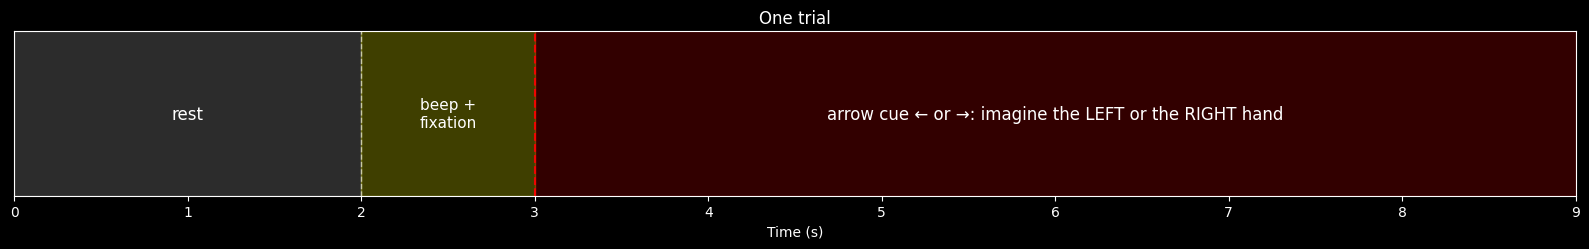

In [3]:
def add_events(ax):
    """Beep (t = 2 s, white) and arrow cue (t = 3 s, red)."""
    ax.axvline(2, color='white', linestyle='--', linewidth=1, alpha=0.6)
    ax.axvline(3, color='red', linestyle='--', linewidth=1.5, alpha=0.9)

fig, ax = plt.subplots(figsize=(16, 2.6))
ax.axvspan(0, 2, color='gray', alpha=0.35)
ax.axvspan(2, 3, color='yellow', alpha=0.25)
ax.axvspan(3, 9, color='red', alpha=0.2)
ax.text(1, 0.5, 'rest', ha='center', va='center', fontsize=12)
ax.text(2.5, 0.5, 'beep +\nfixation', ha='center', va='center', fontsize=11)
ax.text(6, 0.5, 'arrow cue ← or →: imagine the LEFT or the RIGHT hand', ha='center', va='center', fontsize=12)
add_events(ax)
ax.set_xlim(0, 9)
ax.set_yticks([])
ax.set_xlabel('Time (s)')
ax.set_title('One trial')
plt.tight_layout()
plt.show()

---

## Part 1: Statistics Across Trials

### Example 1a: Mean, standard deviation and standard error

Statistics along `axis=0` are computed across trials, separately at every time point.

- Mean across trials: the part of the signal that repeats with the same timing in every trial (event-related potential, ERP).
- Standard deviation across trials: how different the trials are at that time point.
- Standard error of the mean: `std / √n`, the uncertainty of the mean.

left_Cz: (70, 1152)  →  mean across trials: (1152,)
std of a single trial: 0.0857   std of the mean over time: 0.0157


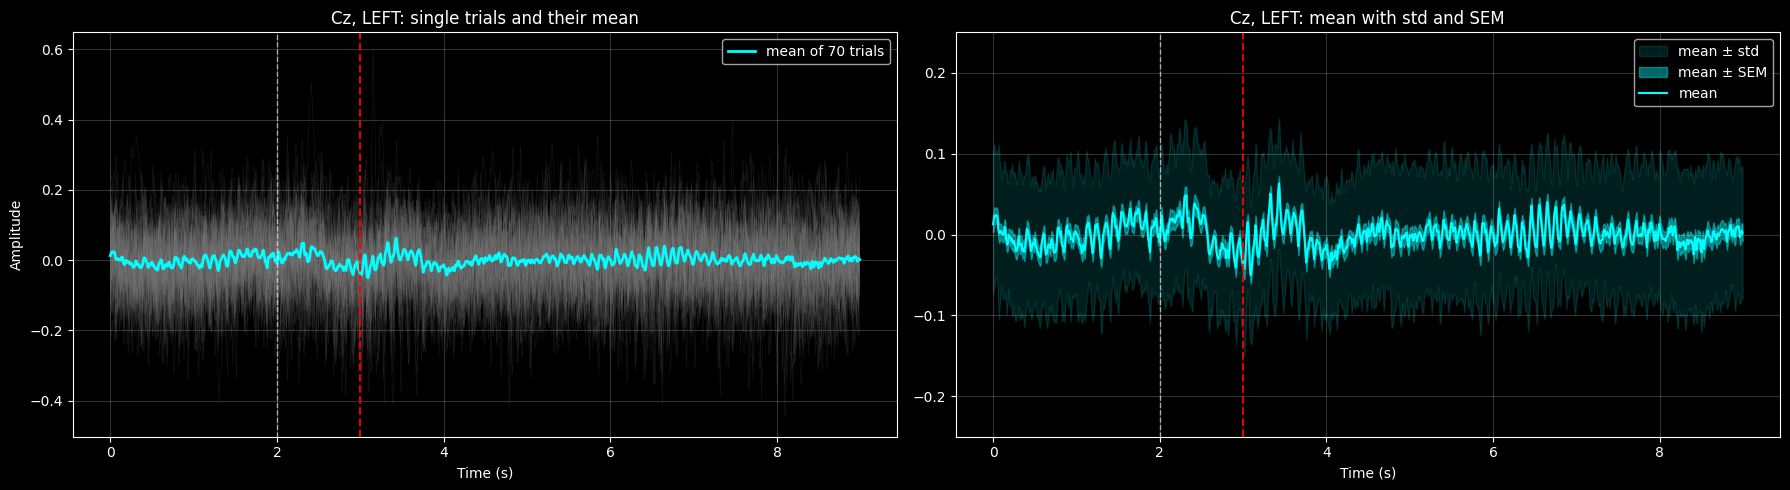

In [4]:
left_Cz = X[y == 1, channel_names.index('Cz'), :]    # (70, 1152)

erp = left_Cz.mean(axis=0)
std = left_Cz.std(axis=0, ddof=1)
sem = std / np.sqrt(left_Cz.shape[0])
print(f"left_Cz: {left_Cz.shape}  →  mean across trials: {erp.shape}")
print(f"std of a single trial: {left_Cz.std():.4f}   std of the mean over time: {erp.std():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharex=True)
axes[0].plot(times, left_Cz.T, color='gray', alpha=0.15, linewidth=0.5)   # .T: one line per column
axes[0].plot(times, erp, color='cyan', linewidth=2, label='mean of 70 trials')
axes[0].set_title('Cz, LEFT: single trials and their mean')
axes[0].set_ylabel('Amplitude')

axes[1].fill_between(times, erp - std, erp + std, color='cyan', alpha=0.12, label='mean ± std')
axes[1].fill_between(times, erp - sem, erp + sem, color='cyan', alpha=0.4, label='mean ± SEM')
axes[1].plot(times, erp, color='cyan', linewidth=1.5, label='mean')
axes[1].set_ylim(-0.25, 0.25)
axes[1].set_title('Cz, LEFT: mean with std and SEM')
for ax in axes:
    add_events(ax)
    ax.set_xlabel('Time (s)')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

The parts of the signal that are not time-locked cancel in the mean. The small deflections after the beep (2 s) and the arrow (3 s) remain .. why ?

### Example 1b: Averaging more trials

If the noise is random, the mean of N trials has a noise level proportional to `1 / √N`. Measured on the baseline (0 – 2 s), where no response is expected.

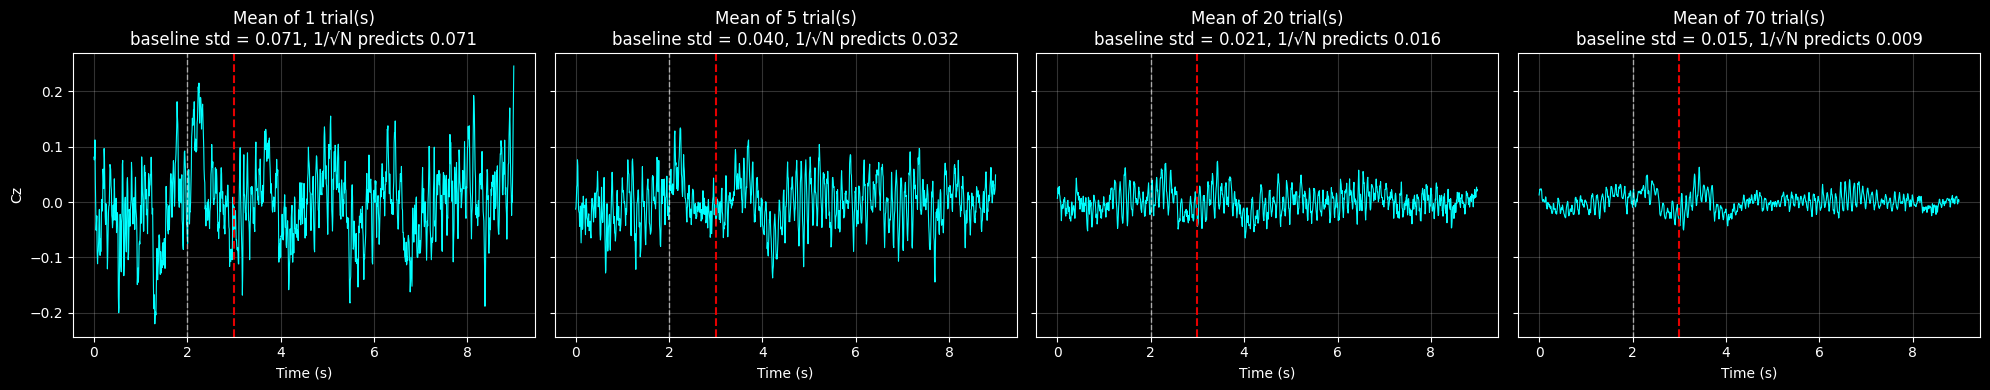

In [5]:
baseline = times < 2
noise_1 = left_Cz[0, baseline].std()

fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, N in zip(axes, [1, 5, 20, 70]):
    mean_N = left_Cz[:N].mean(axis=0)
    ax.plot(times, mean_N, color='cyan', linewidth=0.8)
    add_events(ax)
    ax.set_title(f'Mean of {N} trial(s)\nbaseline std = {mean_N[baseline].std():.3f}, 1/√N predicts {noise_1 / np.sqrt(N):.3f}')
    ax.set_xlabel('Time (s)')
    ax.grid(True, alpha=0.2)
axes[0].set_ylabel('Cz')
plt.tight_layout()
plt.show()

### Practice 1 (10 min)

1. `right_C4`: the RIGHT trials of channel C4.
2. `erp_right_C4`: the mean across trials; `sem_right_C4`: the standard error of the mean (`ddof=1`).
3. `median_right_C4`: the median across trials.
4. `erp_left_C4`: the mean of the LEFT trials of C4; `diff_wave = erp_left_C4 - erp_right_C4`.

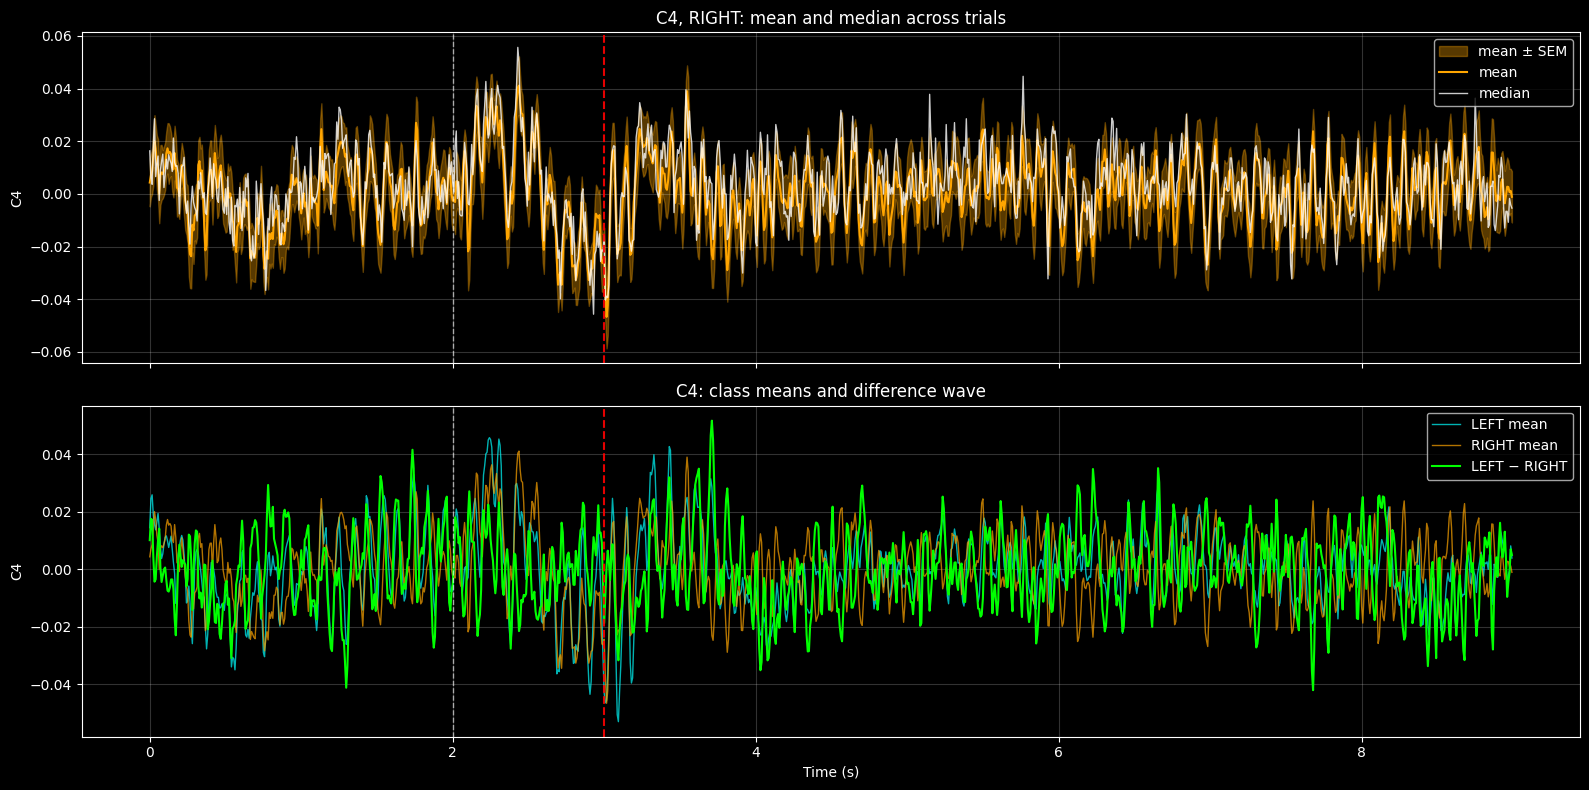

In [11]:
# YOUR CODE HERE

right_C4 = X[y == 2, channel_names.index('C4'), :]
erp_right_C4 = right_C4.mean(axis = 0)
sem_right_C4 = right_C4.std(axis= 0, ddof= 1) / np.sqrt(right_C4.shape[0])
median_right_C4 = np.median(right_C4, axis= 0)

left_c4 = X[y==1 , channel_names.index('C4'), :]
erp_left_C4 = left_c4.mean(axis = 0)

diff_wave = erp_left_C4 - erp_right_C4


fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
axes[0].fill_between(times, erp_right_C4 - sem_right_C4, erp_right_C4 + sem_right_C4, color='orange', alpha=0.35, label='mean ± SEM')
axes[0].plot(times, erp_right_C4, color='orange', linewidth=1.5, label='mean')
axes[0].plot(times, median_right_C4, color='white', linewidth=1, alpha=0.8, label='median')
axes[0].set_title('C4, RIGHT: mean and median across trials')

axes[1].plot(times, erp_left_C4, color='cyan', linewidth=1, alpha=0.7, label='LEFT mean')
axes[1].plot(times, erp_right_C4, color='orange', linewidth=1, alpha=0.7, label='RIGHT mean')
axes[1].plot(times, diff_wave, color='lime', linewidth=1.5, label='LEFT − RIGHT')
axes[1].set_title('C4: class means and difference wave')
axes[1].set_xlabel('Time (s)')
for ax in axes:
    add_events(ax)
    ax.set_ylabel('C4')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

In [12]:
# Tests
_r = X[y == 2, 2, :]
assert right_C4.shape == (70, 1152), "right_C4: (70, 1152)"
assert np.allclose(erp_right_C4, _r.mean(axis=0)), "erp_right_C4: mean over axis 0"
assert np.allclose(sem_right_C4, _r.std(axis=0, ddof=1) / np.sqrt(70)), "sem_right_C4: std (ddof=1) / sqrt(n)"
assert np.allclose(median_right_C4, np.median(_r, axis=0)), "median_right_C4: median over axis 0"
assert np.allclose(erp_left_C4, X[y == 1, 2, :].mean(axis=0)), "erp_left_C4: mean of the LEFT trials"
assert np.allclose(diff_wave, X[y == 1, 2, :].mean(axis=0) - _r.mean(axis=0)), "diff_wave: LEFT mean minus RIGHT mean"
print("Practice 1 passed.")

Practice 1 passed.


---

## Part 2: z-scoring

`z = (x − mean) / std`. The axis over which the mean and std are computed decides what is being compared.

### Example 2a: z-score each channel

Mean and std over all trials and all time (`axis=(0, 2)`). `keepdims=True` keeps the shape (1, 3, 1), so broadcasting subtracts it from the (140, 3, 1152) tensor.

ch_mean: (1, 3, 1), X_chz: (140, 3, 1152)

Channel   mean before   std before   mean after    std after
C3            0.00003      0.08991      0.00000      1.00000
Cz            0.00043      0.08440      0.00000      1.00000
C4            0.00028      0.08462      0.00000      1.00000


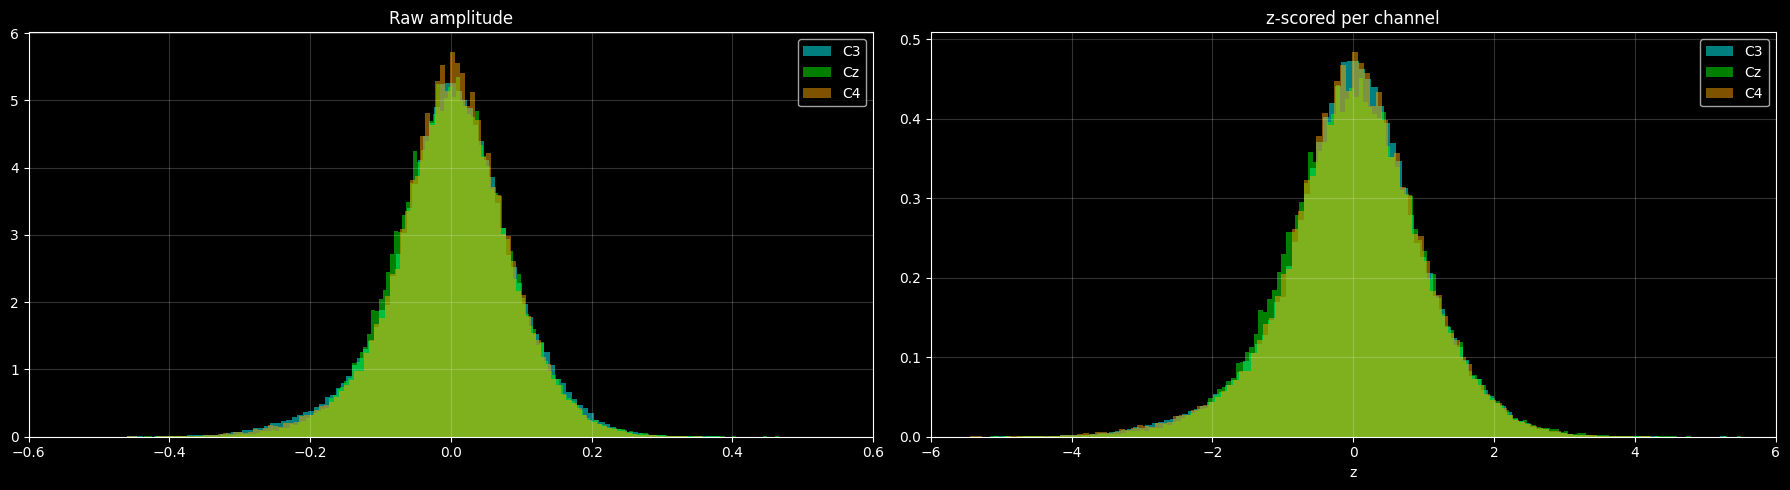

In [13]:
ch_mean = X.mean(axis=(0, 2), keepdims=True)
ch_std = X.std(axis=(0, 2), keepdims=True)
X_chz = (X - ch_mean) / ch_std
print(f"ch_mean: {ch_mean.shape}, X_chz: {X_chz.shape}\n")

print(f"{'Channel':<8} {'mean before':>12} {'std before':>12} {'mean after':>12} {'std after':>12}")
for c, name in enumerate(channel_names):
    print(f"{name:<8} {X[:, c].mean():>12.5f} {X[:, c].std():>12.5f} {X_chz[:, c].mean():>12.5f} {X_chz[:, c].std():>12.5f}")

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for c, (name, color) in enumerate(zip(channel_names, ['cyan', 'lime', 'orange'])):
    axes[0].hist(X[:, c].ravel(), bins=200, alpha=0.5, color=color, label=name, density=True)
    axes[1].hist(X_chz[:, c].ravel(), bins=200, alpha=0.5, color=color, label=name, density=True)
axes[0].set_xlim(-0.6, 0.6)
axes[1].set_xlim(-6, 6)
axes[0].set_title('Raw amplitude')
axes[1].set_title('z-scored per channel')
axes[1].set_xlabel('z')
for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

### Example 2b: Baseline z-score

Mean and std from the baseline (0.5 – 2 s) of the same trial and channel (`axis=2`). Each trial is compared to its own rest period.

base_mean: (140, 3, 1), X_basez: (140, 3, 1152)
baseline mean after z-scoring: -5.64e-18
baseline std, first 5 trials of C3: [1. 1. 1. 1. 1.]


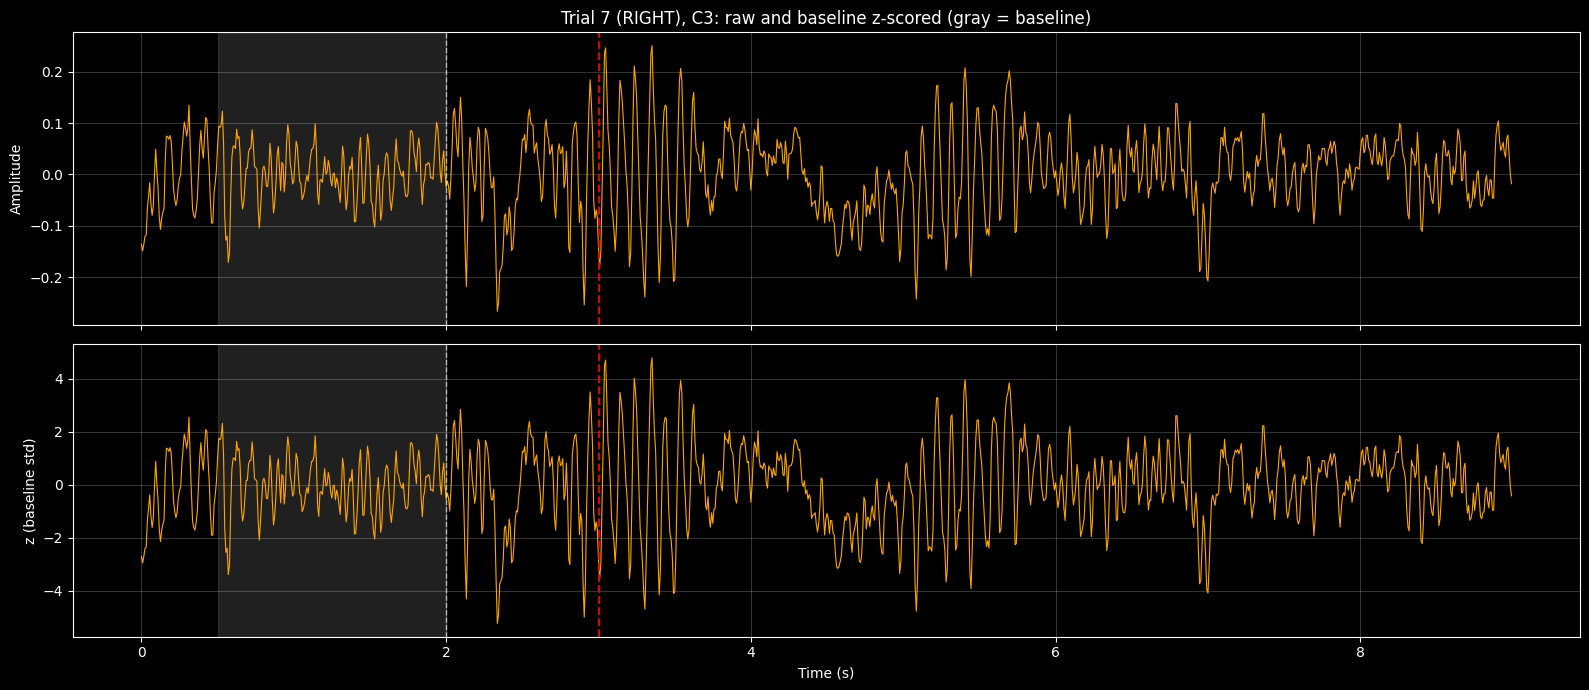

In [14]:
base = (times >= 0.5) & (times < 2)
base_mean = X[:, :, base].mean(axis=2, keepdims=True)    # (140, 3, 1)
base_std = X[:, :, base].std(axis=2, keepdims=True)
X_basez = (X - base_mean) / base_std

print(f"base_mean: {base_mean.shape}, X_basez: {X_basez.shape}")
print(f"baseline mean after z-scoring: {X_basez[:, :, base].mean():.2e}")
print(f"baseline std, first 5 trials of C3: {np.round(X_basez[:5, 0, base].std(axis=1), 3)}")

trial = 7
fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
axes[0].plot(times, X[trial, 0], color=class_colors[y[trial]], linewidth=0.8)
axes[0].set_ylabel('Amplitude')
axes[1].plot(times, X_basez[trial, 0], color=class_colors[y[trial]], linewidth=0.8)
axes[1].set_ylabel('z (baseline std)')
axes[1].set_xlabel('Time (s)')
for ax in axes:
    ax.axvspan(0.5, 2, color='gray', alpha=0.25)
    add_events(ax)
    ax.grid(True, alpha=0.2)
axes[0].set_title(f'Trial {trial} ({class_names[y[trial]]}), C3: raw and baseline z-scored (gray = baseline)')
plt.tight_layout()
plt.show()

In [20]:
# YOUR CODE HERE
max_abs_z = np.max(np.abs(X_chz), axis = (1, 2))
outlier_trials = np.where(max_abs_z > 6)[0]
outlier_trials

array([ 16,  41,  42, 115, 123, 131, 134, 137])

### Practice 2 (8 min)

Detecting outlier trials with the per-channel z-scores `X_chz`.

1. `max_abs_z`: for every trial, the largest |z| over all channels and all time, shape (140,).
2. `outlier_trials`: the trial numbers where `max_abs_z` is above 6.
3. `clean_mask`: True for the trials that are kept.
4. `X_clean`, `y_clean`: the tensor and the labels without the outlier trials.

Outlier trials: [ 16  41  42 115 123 131 134 137]  ['RIGHT', 'RIGHT', 'RIGHT', 'LEFT', 'LEFT', 'LEFT', 'LEFT', 'RIGHT']
X_clean: (132, 3, 1152), LEFT: 66, RIGHT: 66


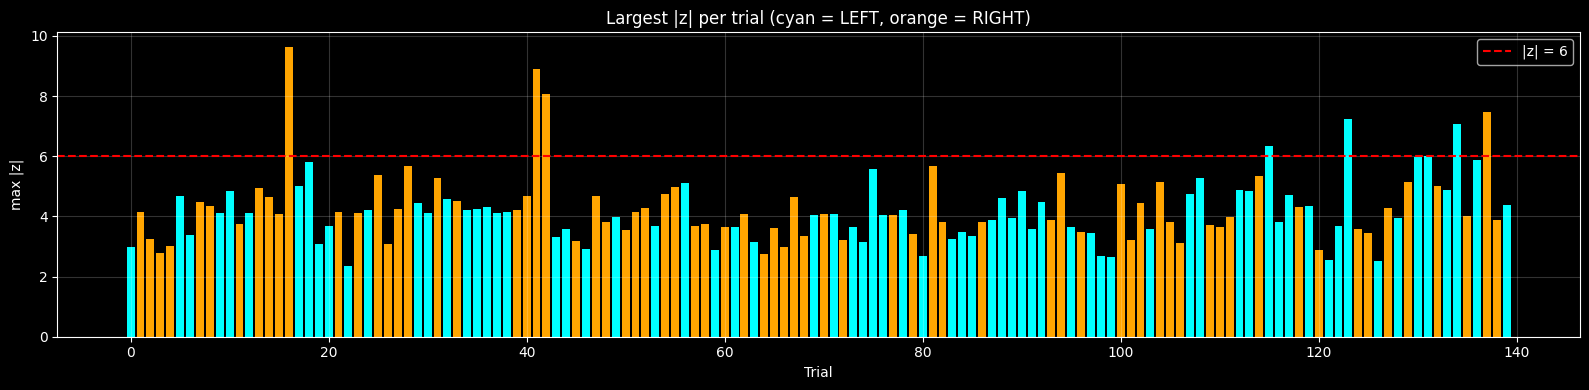

In [21]:
# YOUR CODE HERE
max_abs_z = np.max(np.abs(X_chz), axis = (1, 2))
outlier_trials = np.where(max_abs_z > 6)[0]

clean_mask = max_abs_z <= 6
X_clean = X[clean_mask]
y_clean = y[clean_mask]

print(f"Outlier trials: {outlier_trials}  {[class_names[v] for v in y[outlier_trials]]}")
print(f"X_clean: {X_clean.shape}, LEFT: {np.sum(y_clean == 1)}, RIGHT: {np.sum(y_clean == 2)}")

fig, ax = plt.subplots(figsize=(16, 4))
ax.bar(np.arange(n_trials), max_abs_z, color=[class_colors[v] for v in y])
ax.axhline(6, color='red', linestyle='--', label='|z| = 6')
ax.set_xlabel('Trial')
ax.set_ylabel('max |z|')
ax.set_title('Largest |z| per trial (cyan = LEFT, orange = RIGHT)')
ax.legend()
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

In [22]:
# Tests
_z = np.abs((X - X.mean(axis=(0, 2), keepdims=True)) / X.std(axis=(0, 2), keepdims=True)).max(axis=(1, 2))
assert max_abs_z.shape == (140,) and np.allclose(max_abs_z, _z), "max_abs_z: max of |X_chz| over axis=(1, 2)"
assert np.array_equal(outlier_trials, np.where(_z > 6)[0]), "outlier_trials: max_abs_z > 6"
assert clean_mask.dtype == bool and clean_mask.sum() == 140 - len(outlier_trials), "clean_mask: True for kept trials"
assert X_clean.shape[0] == y_clean.shape[0] == 140 - len(outlier_trials), "X_clean and y_clean lose the same trials"
print("Practice 2 passed.")

Practice 2 passed.


The threshold is a choice: |z| > 5 would remove 25 trials, |z| > 8 only 3. The mean and std used here also include the outliers themselves.

---

## Summary

- `axis=0` is across trials, `axis=1` across channels, `axis=2` across time.
- The mean across trials keeps the time-locked part of the signal (ERP); its noise decreases like `1 / √N`.
- Standard deviation describes the spread of the trials; the standard error describes the uncertainty of the mean.
- A z-score depends on the axis used for the mean and std: per channel for comparing channels and finding outliers, per trial baseline for change from rest.
- `keepdims=True` keeps the reduced axes so that broadcasting works on the full tensor.
- Removing trials is a decision; report the threshold and the number removed.